## Family Size and Academic Performance of Female Secondary School Students

**Student Performance Dataset (Kaggle)**

This document brings together the entire process: research question and hypotheses, data, cleaning, new variables, tests, conclusions, and limitations. To reproduce it, place `student-mat.csv` in the same folder and use Kernel → Restart & Run All

### Table of Contents

1. Research question and hypotheses
2. Data
3. Cleaning and Decision Documentation
4. Feature engineering
5. Baseline test: large family vs. small family
6. Hypotheses H1, H2, and H3
7. Conclusions
8. Limitations

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.power import TTestIndPower

# Saved figures: higher resolution and no cropped labels
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["savefig.bbox"] = "tight"

def summary_table(model):
    """It shows only what matters in a regression: coefficient, p-value, and confidence interval."""
    summary_regression = pd.DataFrame({
        "Coefficient": model.params,
        "P-Value": model.pvalues,
        "CI Lower": model.conf_int()[0],
        "CI Upper": model.conf_int()[1],
    }).round(3)
    print(summary_regression)

## 1. Research question and hypotheses
#### Question:
How does family size affect the academic performance of female secondary school students?

##### Sample delimitation:
* Female students only (sex = F). Performance is measured by the final grade in Mathematics (G3, from 0 to 20).


##### Hypothesis
* **First Hypothesis (H1):** Coming from a large family affects grades negatively the most when the student also lacks free time. The test type used was Moderation (`big_family × lack_freetime` interaction)
* **Second Hypothesis (H2):** Female students from large families have less access to additional educational resources (paid tutoring and extracurricular activities), which is reflected in lower final grades. The test type used was Mediation (`family → resources → grades`)
* **Third Hypothesis (H3):** The negative effect of family size on final grades is stronger in female students whose parents have lower education levels than in those whose parents have higher education levels. The test type used was Moderation (`big_family × high_parent_edu` interaction)

##### Decision rule:
* An effect is considered statistically significant if $p < 0.05$ (established a priori)

##### Transparency note:

* H1 was originally planned as a mediation model using `studytime` and `freetime`. It was later simplified to a moderation model focused only on free time, as it better reflects time pressure from household chores and caring for siblings. Because study time had already been tested before this change, its result is included in Section 6.1 as an extra analysis.

## 2. Data

* **Source:** Dataset from the UCI datasets repository, also available on Kaggle (https://www.kaggle.com/datasets/janiobachmann/math-students/data)
* **Reference:** P. Cortez and A. Silva. Using Data Mining to Predict Secondary School Student Performance. In A. Brito and J. Teixeira Eds., Proceedings of 5th FUture BUsiness TEChnology Conference (FUBUTEC 2008) pp. 5-12, Porto, Portugal, April, 2008, EUROSIS, ISBN 978-9077381-39-7.
* **Content:**  Final scores of students from two Portuguese secondary schools (Gabriel Pereira and Mousinho da Silveira) with several features that might or might not impact the future outcome of these students. This project uses the Mathematics dataset (`student-mat.csv`)

**Variables used in this project**

| Variable | Meaning | Values |
|---|---|---|
| `sex` | Student's sex | F / M (only F is used) |
| `famsize` | Family size | `LE3` (3 or fewer members) / `GT3` (more than 3) |
| `freetime` | Free time after school | 1 (very low) to 5 (very high) |
| `studytime` | Weekly study time | 1 (less than 2 h) to 4 (more than 10 h) |
| `paid` | Extra paid classes within the course subject | yes / no |
| `activities` | Extracurricular activities | yes / no |
| `Medu`, `Fedu` | Mother's and father's education | 0 (none) to 4 (higher education) |
| `absences` | Number of school absences | 0 to 93 (dataset description) |
| `G3` | Final Mathematics grade | 0 to 20 |

In [2]:
df = pd.read_csv("student-mat.csv")   
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 3. Cleaning and Decision Documentation
Each step includes an inspection, the result, and the decision taken.

### 3.1 Structure and Data Types

In [3]:
print("Lines and columns (complete dataset):", df.shape)
print(df.dtypes)

Lines and columns (complete dataset): (395, 33)
school          str
sex             str
age           int64
address         str
famsize         str
Pstatus         str
Medu          int64
Fedu          int64
Mjob            str
Fjob            str
reason          str
guardian        str
traveltime    int64
studytime     int64
failures      int64
schoolsup       str
famsup          str
paid            str
activities      str
nursery         str
higher          str
internet        str
romantic        str
famrel        int64
freetime      int64
goout         int64
Dalc          int64
Walc          int64
health        int64
absences      int64
G1            int64
G2            int64
G3            int64
dtype: object


##### Result: 
395 rows and 33 columns. The numerical variables are stored as integers, and the categorical ones as strings.   
##### Decision: 
The data types are correct, so no conversions are needed. 

### 3.2 Missing values and duplicates

In [4]:
print("------Missing values per column------")
print(df.isnull().sum())
print("Total missing values:", df.isnull().sum().sum())

print("\n-----Duplicate rows -----")
print(df.duplicated().sum())

------Missing values per column------
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64
Total missing values: 0

-----Duplicate rows -----
0


**Result:** 0 missing values across all columns and 0 duplicate rows.

**Decision:** No corrections were required.

### 3.3 Valid Values

In [5]:
for col in df.select_dtypes(include=["object", "str"]).columns:
    print(col, "->", sorted(df[col].unique()))

# Expected ranges according to the dataset documentation
expected_ranges = {
    "age": (15, 22), "Medu": (0, 4), "Fedu": (0, 4),
    "traveltime": (1, 4), "studytime": (1, 4), "failures": (0, 4),
    "famrel": (1, 5), "freetime": (1, 5), "goout": (1, 5),
    "Dalc": (1, 5), "Walc": (1, 5), "health": (1, 5),
    "absences": (0, 93), "G1": (0, 20), "G2": (0, 20), "G3": (0, 20),
}
ranges = pd.DataFrame(
    [(col, lo, hi, df[col].min(), df[col].max(), (~df[col].between(lo, hi)).sum())
     for col, (lo, hi) in expected_ranges.items()],
    columns=["variable", "expected_min", "expected_max", "min", "max", "out_of_range"],
)
print("\n----- Numerical ranges -----")
print(ranges.to_string(index=False))

school -> ['GP', 'MS']
sex -> ['F', 'M']
address -> ['R', 'U']
famsize -> ['GT3', 'LE3']
Pstatus -> ['A', 'T']
Mjob -> ['at_home', 'health', 'other', 'services', 'teacher']
Fjob -> ['at_home', 'health', 'other', 'services', 'teacher']
reason -> ['course', 'home', 'other', 'reputation']
guardian -> ['father', 'mother', 'other']
schoolsup -> ['no', 'yes']
famsup -> ['no', 'yes']
paid -> ['no', 'yes']
activities -> ['no', 'yes']
nursery -> ['no', 'yes']
higher -> ['no', 'yes']
internet -> ['no', 'yes']
romantic -> ['no', 'yes']

----- Numerical ranges -----
  variable  expected_min  expected_max  min  max  out_of_range
       age            15            22   15   22             0
      Medu             0             4    0    4             0
      Fedu             0             4    0    4             0
traveltime             1             4    1    4             0
 studytime             1             4    1    4             0
  failures             0             4    0    3             

**Result:** All categorical variables contain only the documented levels, and every numerical variable lies within its documented range (0 values out of range).

**Decision:** No invalid entries or anomalous values were found; therefore, no records were removed

### 3.4 Filtering: Female Students Only

**Why female students only?** The hypotheses focus on mechanisms such as time pressure from household chores and caring for younger siblings, which tend to fall more heavily on girls in larger families. Restricting the sample keeps the analysis focused on that group. To check whether the family-size pattern is specific to female students, the baseline test is repeated for male students in Section 5.5.


In [6]:
df_all = df.copy()   # full sample, kept for the comparison with male students (Section 5.5)
df = df[df["sex"] == "F"].copy()
print("Number of female students:", len(df))

Number of female students: 208


### 3.5 Outliers: `absences`

count    208.00
mean       6.22
std        9.45
min        0.00
25%        0.00
50%        4.00
75%        8.00
max       75.00
Name: absences, dtype: float64

Upper bound (IQR rule): 20.0
Female students above the upper bound: 12
Maximum: 75


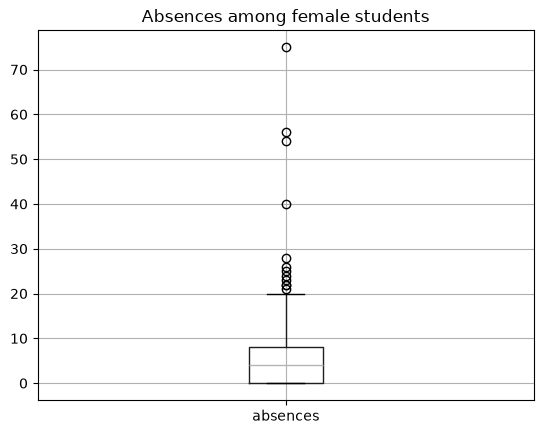

In [7]:
print(df["absences"].describe().round(2))

q1, q3 = df["absences"].quantile([0.25, 0.75])
upper_bound = q3 + 1.5 * (q3 - q1)
print("\nUpper bound (IQR rule):", upper_bound)
print("Female students above the upper bound:", (df["absences"] > upper_bound).sum())
print("Maximum:", df["absences"].max())

df.boxplot(column="absences")
plt.title("Absences among female students")
plt.savefig("cleaning_absences.png")
plt.show()

**Result:** The mean is 6.22 absences, and the median is 4. According to the IQR rule, the upper bound is 20 absences, with 12 female students (approximately 6%) exceeding it. The maximum value is 75.   

**Decision:** All values were retained. Since absences is not included in any of the tested hypotheses, these outliers do not impact the subsequent analyses.  

### 3.6 Zero Final Grades: `G3 = 0`

Female students with G3 = 0: 23 out of 208
...with zero absences: 23
...with G2 = 0: 7
...with a failing G2 (1-9): 15
...with a passing G2 (>= 10): 1
...with passing grades in both G1 and G2: 0
     G1  G2  G3  absences
130  12   0   0         0
131   8   0   0         0
135  11   0   0         0
137   4   0   0         0
146   6   7   0         0
168   6   7   0         0
173   8   7   0         0
221   6   5   0         0
244   7   0   0         0
259  10   9   0         0


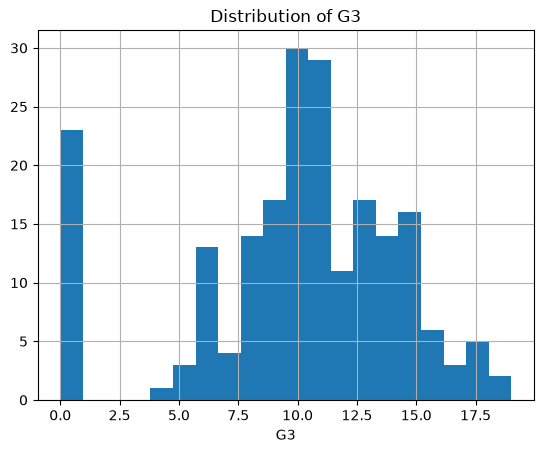

In [8]:
n_zeros = (df["G3"] == 0).sum()
print("Female students with G3 = 0:", n_zeros, "out of", len(df))
zeros = df[df["G3"] == 0]
print("...with zero absences:", (zeros["absences"] == 0).sum())
print("...with G2 = 0:", (zeros["G2"] == 0).sum())
print("...with a failing G2 (1-9):", zeros["G2"].between(1, 9).sum())
print("...with a passing G2 (>= 10):", (zeros["G2"] >= 10).sum())
print("...with passing grades in both G1 and G2:", ((zeros["G1"] >= 10) & (zeros["G2"] >= 10)).sum())
print(zeros[["G1", "G2", "G3", "absences"]].head(10))

df["G3"].hist(bins=20)
plt.title("Distribution of G3")
plt.xlabel("G3")
plt.savefig("cleaning_g3.png")
plt.show()

**Result:** Out of 208 female students, 23 (approximately 11%) have a final grade of zero (`G3 = 0`). Inspecting all 23 cases reveals a distinct pattern:
* All 23 recorded zero absences, which is implausible for students who actually attended the whole year and rules out absenteeism as a recorded cause.
* 7 of them already had a zero in the 2nd period (`G2 = 0`).
* 15 had a failing (but non-zero) `G2` (1 to 9), and only 1 had `G2 = 10`. None had passing grades in both the 1st and 2nd periods.
This behavior is consistent with students who were already struggling and then dropped out or missed the final assessment, although the dataset lacks explicit indicators to confirm it directly.

**Decision:** The zero values were **retained** because zero is a valid grade within the dataset's scale, and we cannot conclusively prove they do not represent actual academic failure. 

### 3.7 Summary of Decisions

| Step | Result | Decision |
| :--- | :--- | :--- |
| **Structure and types** | $395 \times 33$, correct types | No conversion required |
| **Missing values** | 0 | No action required |
| **Duplicates** | 0 | No action required |
| **Unique labels & numerical bounds** | All valid | No records removed |
| **Sex filtering** | 208 female students | `sex == 'F'` only |
| **`absences` outliers** | 12 students above 20 absences, max 75 | Retained (variable not used) |
| **`G3 = 0`** | 23 students (11%) | Retained|

## 4. Feature Engineering

Four main variables were created, along with three auxiliary variables used to construct two of them.

### New Variables

##### `big_family`
* 1 if `famsize == GT3`, 0 if LE3.
* Converts family size into a binary (0/1) variable, required for regressions and group comparisons.
  
##### `lack_freetime`
* `6 - freetime`.
* Inverts the scale (1 to 5) so that higher values indicate less free time (i.e., higher pressure). This simplifies the interpretation of H1.
  
##### `extra_resources`
* `paid_bin + activities_bin` (0 to 2).  
* Combines paid tutoring and extracurricular activities into a single indicator of supplementary educational resources (H2).
      
##### `high_parent_edu`
* 1 if `parent_edu >= 3`, 0 otherwise. 
* Separates students whose parents have, on average, at least secondary education (3 on the scale) from the rest. The cutoff was fixed prior to observing the results (H3).

### Auxiliary variables: 
* `paid_bin` (1 if `"yes"`, 0 if `"no"`)
* `activities_bin` (1 if `"yes"`, 0 if `"no"`)
* `parent_edu` (mean of `Medu` and `Fedu`).

In [9]:
df["big_family"] = (df["famsize"] == "GT3").astype(int)        # 1 = large family
df["lack_freetime"] = 6 - df["freetime"]                     # higher = less free time
df["paid_bin"] = (df["paid"] == "yes").astype(int)
df["activities_bin"] = (df["activities"] == "yes").astype(int)
df["extra_resources"] = df["paid_bin"] + df["activities_bin"]  # 0 to 2
df["parent_edu"] = (df["Medu"] + df["Fedu"]) / 2
df["high_parent_edu"] = (df["parent_edu"] >= 3).astype(int)        # 1 = at least secondary education

print(df["big_family"].value_counts().rename({0: "small family", 1: "large family"}))

big_family
large family    156
small family     52
Name: count, dtype: int64



**Result:** 52 female students from small families and 156 from large families. The small family group is relatively small, which limits statistical power to detect differences (see Section 8).

## 5. Baseline Test: Large vs. Small Family

This test directly addresses the research question: do female students from large families have different final grades than those from small families?

Model: `G3 ~ big_family`. The coefficient of `big_family` represents the difference in mean grades between the two groups.

big_family
0    10.980769
1     9.628205
Name: G3, dtype: float64
            Coefficient  P-Value  CI Lower  CI Upper
Intercept        10.981    0.000     9.724    12.237
big_family       -1.353    0.068    -2.804     0.098


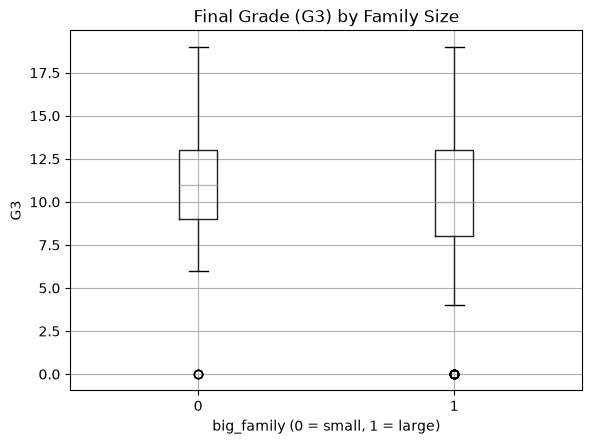

In [10]:
def test_baseline(df):
    print(df.groupby("big_family")["G3"].mean())
    base = smf.ols("G3 ~ big_family", data=df).fit()
    summary_table(base)

def plot_baseline(df):
    df.boxplot(column="G3", by="big_family")
    plt.title("Final Grade (G3) by Family Size")
    plt.suptitle("")
    plt.xlabel("big_family (0 = small, 1 = large)")
    plt.ylabel("G3")
    plt.savefig("baseline_plot.png")
    plt.show()

test_baseline(df)
plot_baseline(df)

### Result:


| | Small family | Large family |
| :--- | :--- | :--- |
| **Mean of `G3`** | 10.98 | 9.63 |


The coefficient of `big_family` is **-1.35** ($p = 0.068$; 95% CI $[-2.80, 0.10]$).

**Interpretation:** Female students from large families score, on average, 1.35 points lower. The $p$-value is slightly above 0.05 and the confidence interval includes zero; therefore, the difference is **not statistically significant** and the evidence is inconclusive. The direction matches expectations, but the sample size does not allow us to rule out random chance.

**In practice:** In this sample, students from larger families scored lower, but the difference is not clear enough to be considered definitive.

### 5.1 Sensitivity analysis: Does the result change without `G3 = 0`?

Since zero values were retained (Section 3.6), the baseline test is repeated without them to verify whether the conclusion depends on this methodological choice.

In [11]:
with_zeros = smf.ols("G3 ~ big_family", data=df).fit()
without_zeros = smf.ols("G3 ~ big_family", data=df[df["G3"] > 0]).fit()

print("With zeros -> coef:", round(with_zeros.params["big_family"], 3),
      "| p:", round(with_zeros.pvalues["big_family"], 3),
      "| N:", int(with_zeros.nobs))
print("Without zeros -> coef:", round(without_zeros.params["big_family"], 3),
      "| p:", round(without_zeros.pvalues["big_family"], 3),
      "| N:", int(without_zeros.nobs))

With zeros -> coef: -1.353 | p: 0.068 | N: 208
Without zeros -> coef: -0.609 | p: 0.251 | N: 185



**Result:** Without the 23 students with `G3 = 0` ($N = 185$), the coefficient for `big_family` changes from -1.35 to -0.61 ($p = 0.251$).

**Interpretation:** The zeros influence the magnitude of the result, which should be reported as a limitation. The primary analysis with zeros is retained, as decided beforehand, and this version is reported as a robustness check.


### 5.2 Robustness: unequal groups and non-normal grades

The two groups have very different sizes (52 vs. 156) and `G3` is not normally distributed (it has a spike at zero). The baseline result is therefore checked with three alternatives that rely on weaker assumptions: OLS with heteroskedasticity-robust (HC3) standard errors, Welch's t-test (does not assume equal variances), and the Mann-Whitney U test (non-parametric, compares ranks instead of means).

In [12]:
big = df.loc[df["big_family"] == 1, "G3"]
small = df.loc[df["big_family"] == 0, "G3"]

print("OLS with robust (HC3) standard errors:")
summary_table(smf.ols("G3 ~ big_family", data=df).fit(cov_type="HC3"))

welch = stats.ttest_ind(big, small, equal_var=False)
mann_whitney = stats.mannwhitneyu(big, small)
print(f"\nWelch t-test:   t = {welch.statistic:.2f}, p = {welch.pvalue:.3f}")
print(f"Mann-Whitney U: U = {mann_whitney.statistic:.0f}, p = {mann_whitney.pvalue:.3f}")

OLS with robust (HC3) standard errors:
            Coefficient  P-Value  CI Lower  CI Upper
Intercept        10.981    0.000     9.848    12.114
big_family       -1.353    0.051    -2.709     0.004

Welch t-test:   t = -1.97, p = 0.052
Mann-Whitney U: U = 3399, p = 0.079


**Result:**

| Test | p-value |
| :--- | :---: |
| OLS (classical standard errors, Section 5) | 0.068 |
| OLS with robust (HC3) standard errors | 0.051 (95% CI $[-2.71, 0.00]$) |
| Welch t-test | 0.052 |
| Mann-Whitney U | 0.079 |

**Interpretation:** All four tests give p-values between 0.05 and 0.08. The robust versions are slightly closer to the threshold, but none falls below 0.05. The conclusion does not depend on the test chosen: the difference is borderline and not statistically significant.

### 5.3 Control variables

Other characteristics could be related to both family size and grades. The baseline model is repeated adding `age`, `school`, `address` (urban/rural) and `failures` (number of past class failures).

`failures` needs care: past failures may themselves be partly caused by the family context, so controlling for them can absorb part of the very effect being studied. For this reason the model is shown with and without `failures`.

In [13]:
print("------ With age, school, address and failures ------")
summary_table(smf.ols("G3 ~ big_family + age + C(school) + C(address) + failures", data=df).fit())

print("\n------ Without failures ------")
summary_table(smf.ols("G3 ~ big_family + age + C(school) + C(address)", data=df).fit())

------ With age, school, address and failures ------
                 Coefficient  P-Value  CI Lower  CI Upper
Intercept             12.418    0.009     3.159    21.677
C(school)[T.MS]        0.189    0.858    -1.894     2.273
C(address)[T.U]        0.700    0.379    -0.867     2.268
big_family            -1.118    0.123    -2.542     0.307
age                   -0.101    0.715    -0.648     0.446
failures              -1.627    0.000    -2.511    -0.744

------ Without failures ------


                 Coefficient  P-Value  CI Lower  CI Upper
Intercept             13.768    0.005     4.264    23.271
C(school)[T.MS]        0.398    0.714    -1.743     2.540
C(address)[T.U]        0.827    0.313    -0.785     2.439
big_family            -1.308    0.079    -2.771     0.154
age                   -0.210    0.459    -0.770     0.349


**Result:**

| Model | `big_family` coefficient | p-value | 95% CI |
| :--- | :---: | :---: | :---: |
| Baseline (no controls) | -1.35 | 0.068 | $[-2.80, 0.10]$ |
| + age, school, address | -1.31 | 0.079 | $[-2.77, 0.15]$ |
| + age, school, address, failures | -1.12 | 0.123 | $[-2.54, 0.31]$ |

**Interpretation:** Age, school and address barely change the estimate. Adding `failures` reduces it to -1.12. Past failures are by far the strongest predictor of the final grade (-1.63 points per failure, $p < 0.001$), and part of the family difference overlaps with them. The family coefficient keeps the same direction in all models, and remains non-significant.

### 5.4 Statistical power

How large would a difference need to be for this sample to detect it reliably? The minimum detectable effect is calculated for a two-group comparison with 52 and 156 students, $\alpha = 0.05$ and 80% power.

In [14]:
power_analysis = TTestIndPower()
n_small = int((df["big_family"] == 0).sum())
n_big = int((df["big_family"] == 1).sum())

# Pooled standard deviation of G3, used to convert Cohen's d into grade points
pooled_sd = (((n_small - 1) * small.var() + (n_big - 1) * big.var()) / (n_small + n_big - 2)) ** 0.5

min_d = power_analysis.solve_power(nobs1=n_small, ratio=n_big / n_small, alpha=0.05, power=0.8)
observed_diff = big.mean() - small.mean()
power_observed = power_analysis.power(effect_size=abs(observed_diff) / pooled_sd,
                                      nobs1=n_small, ratio=n_big / n_small, alpha=0.05)

print(f"Pooled SD of G3: {pooled_sd:.2f}")
print(f"Minimum detectable effect (80% power): d = {min_d:.2f} -> {min_d * pooled_sd:.2f} grade points")
print(f"Power to detect the observed difference ({observed_diff:.2f} points): {power_observed:.0%}")

Pooled SD of G3: 4.60
Minimum detectable effect (80% power): d = 0.45 -> 2.07 grade points
Power to detect the observed difference (-1.35 points): 45%


**Result:** With these group sizes, only a difference of about **2.1 points** (Cohen's $d \approx 0.45$) would be detected with 80% probability. The observed difference (1.35 points) would be detected only about **45%** of the time.

**Interpretation:** The study is underpowered for differences of the size observed. A non-significant result here means "not enough evidence", not "no effect".

### 5.5 Comparison with male students

To check whether the pattern is specific to female students (Section 3.4), the baseline test is repeated for the 187 male students. A model with the full sample then tests whether the family effect differs by sex (`big_family × male` interaction).

In [15]:
boys = df_all[df_all["sex"] == "M"].assign(big_family=lambda d: (d["famsize"] == "GT3").astype(int))

print("------ Male students: group sizes and mean G3 ------")
print(boys.groupby("big_family")["G3"].agg(["count", "mean"]).round(2))

print("\n------ Male students: G3 ~ big_family ------")
summary_table(smf.ols("G3 ~ big_family", data=boys).fit())

full = df_all.assign(
    big_family=lambda d: (d["famsize"] == "GT3").astype(int),
    male=lambda d: (d["sex"] == "M").astype(int),
)
print("\n------ Full sample: does the family effect differ by sex? ------")
summary_table(smf.ols("G3 ~ big_family * male", data=full).fit())

------ Male students: group sizes and mean G3 ------
            count   mean
big_family              
0              62  11.02
1             125  10.86

------ Male students: G3 ~ big_family ------
            Coefficient  P-Value  CI Lower  CI Upper
Intercept        11.016    0.000     9.887    12.145
big_family       -0.152    0.828    -1.533     1.229

------ Full sample: does the family effect differ by sex? ------
                 Coefficient  P-Value  CI Lower  CI Upper
Intercept             10.981    0.000     9.739    12.222
big_family            -1.353    0.064    -2.786     0.081
male                   0.035    0.967    -1.648     1.719
big_family:male        1.200    0.238    -0.797     3.198


**Result:**

| | Small family | Large family | `big_family` coefficient | p-value |
| :--- | :---: | :---: | :---: | :---: |
| **Female students** (N = 208) | 10.98 | 9.63 | -1.35 | 0.068 |
| **Male students** (N = 187) | 11.02 | 10.86 | -0.15 | 0.828 |

Interaction `big_family:male` (full sample, N = 395): **1.20** ($p = 0.238$; 95% CI $[-0.80, 3.20]$).

**Interpretation:** Among male students there is practically no difference between large and small families (-0.15 points). The gap is therefore concentrated among female students, which is consistent with the choice of focusing on them. However, the interaction is not significant and its confidence interval is wide, so the data do not allow us to claim that the family effect is really different for boys and girls.

**In practice:** Boys from large families do not score lower. Girls might, but the evidence that the difference is specific to them is still weak.

## 6. Hypotheses

### 6.1 First Hypothesis (H1):

<ins>Coming from a large family affects grades negatively the most when the student also lacks free time</ins>

**How we test it:**

1. **Step 1 (Complementary test):** Test if larger families have less free time (`lack_freetime ~ big_family`).
2. **Step 2 (Main test):** Run the combined model `G3 ~ big_family * lack_freetime_c`, where `lack_freetime_c` is `lack_freetime` centred at its mean (so that the `big_family` coefficient refers to a student with average free time).
   * Look at the interaction row **`big_family:lack_freetime_c`**.
   * If its coefficient is **negative** and **statistically significant** ($p < 0.05$), H1 is confirmed.

In [16]:
def test_h1_free_time(df):
    print("--------H1: Free time----------")
    print(df.groupby("big_family")["lack_freetime"].mean())
    summary_table(smf.ols("lack_freetime ~ big_family", data=df).fit())

    print("\n-------H1: Does the large family effect depend on free time? -------")
    # Centre the moderator so that the big_family coefficient is the effect at average free time
    centred = df.assign(lack_freetime_c=df["lack_freetime"] - df["lack_freetime"].mean())
    summary_table(smf.ols("G3 ~ big_family * lack_freetime_c", data=centred).fit())

def plot_h1(df):
    # Separate panels: studytime (1-4) and lack_freetime (1-5) use different scales
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    panels = [("studytime", "Study time (1-4)"), ("lack_freetime", "Lack of free time (1-5)")]
    for ax, (column, label) in zip(axes, panels):
        sns.barplot(data=df, x="big_family", y=column, ax=ax)
        ax.set_title(label)
        ax.set_xlabel("big_family (0 = small, 1 = large)")
        ax.set_ylabel("Mean")
    fig.suptitle("H1: Study time and lack of free time by family size")
    plt.savefig("h1_plot.png")
    plt.show()

test_h1_free_time(df)

--------H1: Free time----------
big_family
0    2.903846
1    3.019231
Name: lack_freetime, dtype: float64
            Coefficient  P-Value  CI Lower  CI Upper
Intercept         2.904    0.000     2.646     3.162
big_family        0.115    0.446    -0.183     0.413

-------H1: Does the large family effect depend on free time? -------


                            Coefficient  P-Value  CI Lower  CI Upper
Intercept                        10.966    0.000     9.697    12.234
big_family                       -1.341    0.072    -2.804     0.122
lack_freetime_c                  -0.175    0.809    -1.605     1.255
big_family:lack_freetime_c        0.295    0.720    -1.325     1.915


**Complementary analysis: Study time.** Study time (`studytime`) was not used as a moderator (as it reflects student behavior rather than a condition imposed by the family context), but it was tested to determine whether it differs between the two groups.

In [17]:
print(df.groupby("big_family")["studytime"].mean())
summary_table(smf.ols("studytime ~ big_family", data=df).fit())

big_family
0    2.250000
1    2.288462
Name: studytime, dtype: float64


            Coefficient  P-Value  CI Lower  CI Upper
Intercept         2.250    0.000     2.033     2.467
big_family        0.038    0.762    -0.212     0.289


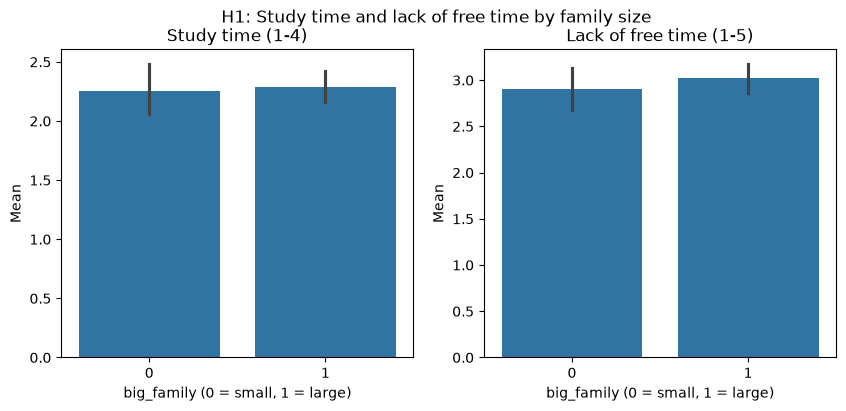

In [18]:
plot_h1(df)


**Result:**

| Test | Coefficient | p-value | 95% CI |
| :--- | :---: | :---: | :---: |
| Large family → lack of free_time | 0.115 | 0.446 | $[-0.18, 0.41]$ |
| Large family → study time (complementary) | 0.038 | 0.762 | $[-0.21, 0.29]$ |
| Interaction `big_family:lack_freetime_c` → `G3` | 0.295 | 0.720 | $[-1.33, 1.92]$ |

**Interpretation:** Students from large families report, on average, 0.12 points higher lack of free time (on a 1 to 5 scale), which is a small and non-significant difference. Study time also does not differ between groups (2.25 vs. 2.29). The interaction is practically null and shows a sign opposite to what was predicted, with a confidence interval that comfortably includes zero. **H1 is not confirmed.**

*Reading note:* Because `lack_freetime` was centred, the `big_family` coefficient in the interaction model (-1.34, $p = 0.072$) is the family effect for a student with average free time, which is almost identical to the baseline (-1.35). Centring does not change the interaction coefficient. The plot shows the two variables in separate panels because they use different scales.

**In practice:** Having less free time or studying less does not appear to be the reason why students from large families tend to have lower grades.

### 6.2 Second Hypothesis (H2): 
<ins>Female students from large families have less access to additional educational resources (paid tutoring and extracurricular activities), which is reflected in lower final grades. </ins>

**How we test it:**
1. **Step 1:** Do large families have fewer resources? (`extra_resources ~ big_family`).
2. **Step 2:**  Do resources affect grades, and does the family effect decrease when controlling for them? (`G3 ~ big_family + extra_resources`, comparing the `big_family` coefficient with the baseline test value of -1.35)

--------------H2: Resource Proportions and Total Mean ------------
            Proportion: Tutoring (0-1)  Proportion: Activities (0-1)  \
big_family                                                             
0                                0.481                         0.442   
1                                0.532                         0.468   

            Mean Total Resources (0-2)  
big_family                              
0                                0.923  
1                                1.000  

------------ H2 Step 1: Do large families have fewer resources? -----------
            Coefficient  P-Value  CI Lower  CI Upper
Intercept         0.923    0.000     0.735     1.111
big_family        0.077    0.486    -0.140     0.294

------------ H2 Step 2: Do resources affect grades? ----------
                 Coefficient  P-Value  CI Lower  CI Upper
Intercept             11.114    0.000     9.595    12.632
big_family            -1.341    0.071    -2.797     0.114
extra_

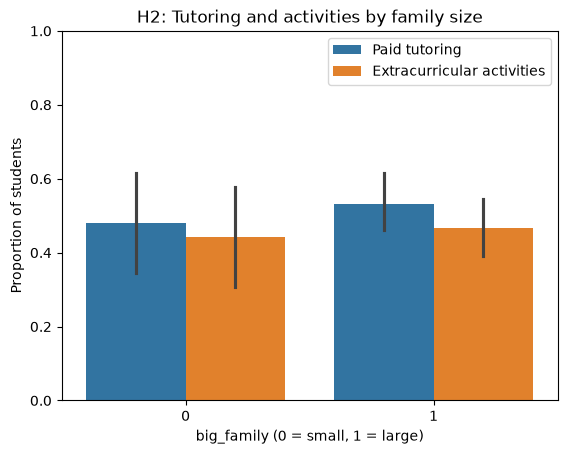

In [19]:
def test_h2_resources(df):
    print("--------------H2: Resource Proportions and Total Mean ------------")
    
    # Group and calculate means
    h2_means = df.groupby("big_family")[["paid_bin", "activities_bin", "extra_resources"]].mean()
    
    # Rename columns to make the distinction crystal clear in the output
    h2_means.columns = [
        "Proportion: Tutoring (0-1)", 
        "Proportion: Activities (0-1)", 
        "Mean Total Resources (0-2)"
    ]
    
    print(h2_means.round(3))

    print("\n------------ H2 Step 1: Do large families have fewer resources? -----------")
    summary_table(smf.ols("extra_resources ~ big_family", data=df).fit())

    print("\n------------ H2 Step 2: Do resources affect grades? ----------")
    summary_table(smf.ols("G3 ~ big_family + extra_resources", data=df).fit())

    print("\n------------ H2 extra: each resource separately ----------")
    print("Paid tutoring ~ big_family")
    summary_table(smf.ols("paid_bin ~ big_family", data=df).fit())
    print("\nActivities ~ big_family")
    summary_table(smf.ols("activities_bin ~ big_family", data=df).fit())
    print("\nG3 ~ big_family + both resources")
    summary_table(smf.ols("G3 ~ big_family + paid_bin + activities_bin", data=df).fit())

def plot_h2(df):
    long_df = df.melt(
        id_vars="big_family",
        value_vars=["paid_bin", "activities_bin"],
        var_name="resource",
        value_name="value"
    )

    # More readable names in the legend
    long_df["resource"] = long_df["resource"].replace({
        "paid_bin": "Paid tutoring",
        "activities_bin": "Extracurricular activities"
    })

    sns.barplot(data=long_df, x="big_family", y="value", hue="resource")

    plt.title("H2: Tutoring and activities by family size")
    plt.xlabel("big_family (0 = small, 1 = large)")
    plt.ylabel("Proportion of students")
    plt.ylim(0, 1)
    plt.legend(title="")
    plt.savefig("h2_plot.png")
    plt.show()

test_h2_resources(df)
plot_h2(df)

### Results

| Resource | Small family | Large family |
| :--- | :---: | :---: |
| Paid tutoring | 48.1% | 53.2% |
| Extracurricular activities | 44.2% | 46.8% |
| `extra_resources` (mean, 0 to 2) | 0.92 | 1.00 |

| Test | Coefficient | p-value | 95% CI |
| :--- | :---: | :---: | :---: |
| Step 1: `big_family` $\rightarrow$ `extra_resources` | 0.077 | 0.486 | [-0.14, 0.29] |
| Step 2: `extra_resources` $\rightarrow$ `G3` | -0.144 | 0.757 | [-1.06, 0.78] |
| Step 2: `big_family` $\rightarrow$ `G3` (controlling for resources) | -1.341 | 0.071 | [-2.80, 0.11] |

**Interpretation:** Students from large families do not have fewer resources; they actually have slightly more (opposite to the hypothesis, but not statistically significant). Resources are also not associated with grades, and the family coefficient remains virtually unchanged when controlling for them (moving from -1.35 to -1.34). Both links of the mediation chain fail, meaning there is no mediation. **H2 is not confirmed.**

**Each resource separately.** Combining tutoring and activities into one index could hide opposite effects, so they were also tested separately:

| Test | Coefficient | p-value | 95% CI |
| :--- | :---: | :---: | :---: |
| `big_family` → paid tutoring | 0.051 | 0.524 | [-0.11, 0.21] |
| `big_family` → activities | 0.026 | 0.749 | [-0.13, 0.18] |
| Paid tutoring → `G3` (model with both) | 0.722 | 0.258 | [-0.53, 1.98] |
| Activities → `G3` (model with both) | -1.013 | 0.114 | [-2.27, 0.24] |
| `big_family` → `G3` (controlling for both) | -1.364 | 0.064 | [-2.81, 0.08] |

The two resources point in opposite directions (tutoring positive, activities negative), which partly explains why the combined index shows no association. Neither is significant, and the family coefficient is unchanged, so the conclusion stays the same.

*Caution:* `paid` refers to extra paid classes in Mathematics. Students may take them *because* they are struggling, so the association between tutoring and grades can run in the opposite direction and is not a clean measure of access to resources.

**In practice:** In this sample, large families do not lack tutoring or activities, and educational resources are not the reason behind the grade differences.

### 6.3 Third Hypothesis (H3): 
<ins>Does parental education alter the family effect?</ins>

**Hypothesis:** The negative effect of family size on final grades is stronger in female students whose parents have lower education levels than in those whose parents have higher education levels.

**How it is tested:** Model `G3 ~ big_family * high_parent_edu`. The decisive line is the `big_family:high_parent_edu` interaction. First, confirm that each of the four groups has a sufficient number of students.

------ H3: number of students in each group (each cell must have sufficient observations) -----------
high_parent_edu   0   1
big_family             
0                30  22
1                81  75

-----------H3: mean G3 by group------------------
high_parent_edu  big_family
0                0             10.133333
                 1              8.641975
1                0             12.136364
                 1             10.693333
Name: G3, dtype: float64

-------------H3: does the family effect depend on parental education? -----------
                            Coefficient  P-Value  CI Lower  CI Upper
Intercept                        10.133    0.000     8.512    11.754
big_family                       -1.491    0.123    -3.389     0.406
high_parent_edu                   2.003    0.115    -0.489     4.495
big_family:high_parent_edu        0.048    0.974    -2.821     2.918


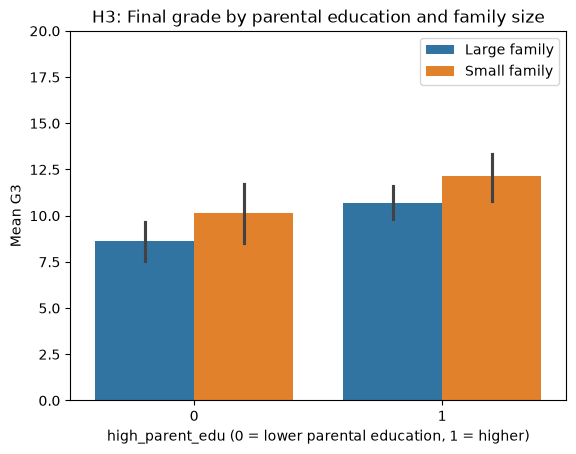

In [20]:
def test_h3_parent_education(df):
    print("------ H3: number of students in each group (each cell must have sufficient observations) -----------")
    print(pd.crosstab(df["big_family"], df["high_parent_edu"]))

    print("\n-----------H3: mean G3 by group------------------")
    print(df.groupby(["high_parent_edu", "big_family"])["G3"].mean())

    print("\n-------------H3: does the family effect depend on parental education? -----------")
    # Look at the big_family:high_parent_edu row (the interaction)
    summary_table(smf.ols("G3 ~ big_family * high_parent_edu", data=df).fit())

def plot_h3(df):
    # More readable labels for the legend
    plot_df = df.assign(family_size=df["big_family"].map({0: "Small family", 1: "Large family"}))

    sns.barplot(data=plot_df, x="high_parent_edu", y="G3", hue="family_size")

    plt.title("H3: Final grade by parental education and family size")
    plt.xlabel("high_parent_edu (0 = lower parental education, 1 = higher)")
    plt.ylabel("Mean G3")
    plt.ylim(0, 20)
    plt.legend(title="")
    plt.savefig("h3_plot.png")
    plt.show()

test_h3_parent_education(df)
plot_h3(df)

### Results

**Number of students per group:**

| | Lower parental education (0) | Higher parental education (1) |
| :--- | :---: | :---: |
| **Small family (0)** | 30 | 22 |
| **Large family (1)** | 81 | 75 |

**Mean of `G3`:**

| | Small family | Large family | Difference |
| :--- | :---: | :---: | :---: |
| **Lower parental education** | 10.13 | 8.64 | -1.49 |
| **Higher parental education** | 12.14 | 10.69 | -1.44 |

Interaction `big_family` $\times$ `high_parent_edu`: **0.048** ($p = 0.974$; 95% CI $[-2.82; 2.92]$).

**Interpretation:** All four cells have at least 22 students, though small family cells have fewer observations. The difference between large and small families is virtually identical across both parental education groups (around $-1.5$ points), and the interaction is practically null. The confidence interval is wide, meaning the sample does not rule out moderate differences either. **H3 is not confirmed.**

**In practice:** Parental education does not appear to either mitigate or aggravate the effect of family size.

## 7. Conclusions

#### 1. There is a difference of about 1.4 points, but it remains inconclusive
![Final Grade (G3) by Family Size](baseline_plot.png)

Students from large families have grades about 1.35 points lower ($p = 0.068$). Robust standard errors, Welch's t-test and the Mann-Whitney test give the same picture (p between 0.05 and 0.08), and the estimate stays between -1.1 and -1.3 when age, school, address and past failures are controlled for. In practice: the difference points in the expected direction, but it is not statistically significant and the sample size does not allow us to tell whether it is real.

#### 2. Free time does not alter the family effect (H1).
![H1: Study time and lack of free time by family size](h1_plot.png)

Neither free time nor study time differs between students from large and small families, and the effect of family size on grades does not vary with free time ($p = 0.720$). *In practice:* lack of time does not appear to explain the difference in grades.

#### 3. Educational resources do not explain the difference (H2).
![H2: Tutoring and activities by family size](h2_plot.png)

Large families do not have fewer tutoring sessions or activities (53% vs. 48% with tutoring), and resources are not associated with grades ($p = 0.757$). *In practice:* the lack of money for tutoring or activities is not the visible cause of the difference.

#### 4. Parental education does not modify the effect (H3).
![H3: Final grade by parental education and family size](h3_plot.png)

A difference of about -1.5 points appears with both lower- and higher-educated parents (interaction $p = 0.974$). *In practice:* having more educated parents does not appear to protect students from the effect of a large family.

#### 5. The pattern does not appear among male students
Boys from large and small families have practically the same mean grade (-0.15 points, $p = 0.828$). The difference between boys and girls in the family effect is not significant ($p = 0.238$), so it cannot be said that the effect is specific to girls. *In practice:* the possible disadvantage of large families appears only among female students, but more data would be needed to confirm it.

**Synthesis.** The baseline test shows students from large families scoring about 1.35 points lower ($p = 0.068$). The estimates from the other models (-1.34 in H2, -1.49 and -1.44 in H3) are close to this value, but they come from the same 208 students and therefore are not independent confirmations; they only show that the estimate is stable when other variables are added. None of the mechanisms or conditions tested (time, resources, parental education) explain or modify the effect. Without the 23 zero grades, the difference shrinks to -0.61 ($p = 0.251$). With these group sizes the study had only about 45% power to detect a difference of 1.35 points, so a non-significant result is expected even if the effect is real. Overall, the data are compatible with a modest disadvantage for students from large families, but the evidence is inconclusive and no mechanism could be identified.

## 8. Limitations

- **Small sample size.** There are only 208 female students, and just 52 in small families (22 to 30 in the H3 cells). With so few students, only differences of about 2.1 points or more can be detected with 80% power, and the power to detect the observed 1.35 points is about 45% (Section 5.4).
- **Binary family size variable (`famsize`).** It distinguishes families with 3 or fewer members from those with more than 3, lacking sibling count or birth order, and thus does not measure "how large" the family is.
- **Indirect indicators.** `freetime` is a perception of free time and does not measure household chores or sibling care. `paid` refers exclusively to Mathematics tutoring. Parental education was averaged and then dichotomized.
- **Mathematics only.** Conclusions do not necessarily generalize to other subjects.
- **Zero grades.** The 23 students with $G3 = 0$ may represent dropouts rather than actual academic performance (see section 5.1).
- **Association, not causality.** Even a significant effect would only demonstrate an association in this sample.
- **Multiple testing.** Several tests were conducted without correction for multiple comparisons. This includes the robustness checks, controls and sex comparison in Sections 5.2 to 5.5. Since none were significant, this does not alter the conclusions.
- **Limited controls.** Section 5.3 controls for `age`, `school`, `address` and `failures`, but important factors such as household income or the actual number of siblings are not in the dataset. `failures` may also be partly a consequence of the family context, which makes its role as a control ambiguous.
- **Comparison by sex.** The comparison with male students (Section 5.5) is exploratory and was added after the main analysis. The interaction test has even less power than the main test.
